In [1]:
import torch
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

#Dataset loading, demonstration and normalization

100%|██████████| 170M/170M [03:57<00:00, 717kB/s]


Обучающая выборка: 50000 примеров
Тестовая выборка: 10000 примеров
Форма одного изображения: torch.Size([3, 32, 32])
Метка класса (пример): 6 (frog)
Количество классов: 10
Форма батча изображений: torch.Size([128, 3, 32, 32])
Форма батча меток: torch.Size([128])


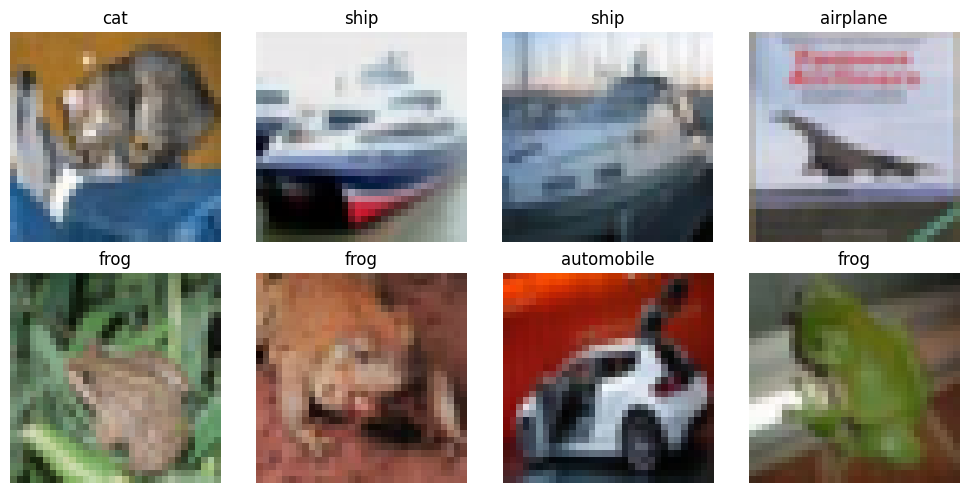

In [2]:
raw_train = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
train_pixels = raw_train.data / 255.0
mean = train_pixels.mean(axis=(0, 1, 2))
std = train_pixels.std(axis=(0, 1, 2))

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=False, transform=train_transform
)
test_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=test_transform
)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = train_dataset.classes

sample_image, sample_label = train_dataset[0]
print(f"Обучающая выборка: {len(train_dataset)} примеров")
print(f"Тестовая выборка: {len(test_dataset)} примеров")
print(f"Форма одного изображения: {sample_image.shape}")
print(f"Метка класса (пример): {sample_label} ({classes[sample_label]})")
print(f"Количество классов: {len(classes)}")

images, labels = next(iter(test_loader))
print(f"Форма батча изображений: {images.shape}")
print(f"Форма батча меток: {labels.shape}")

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for idx, ax in enumerate(axes.flat):
    img = images[idx].permute(1, 2, 0).numpy() * std + mean
    img = np.clip(img, 0, 1)
    ax.imshow(img)
    ax.set_title(classes[labels[idx]])
    ax.axis('off')

plt.tight_layout()
plt.show()

#NN implementation

In [3]:
import torch.nn as nn

In [4]:
def conv_block(in_channels, out_channels, pool=False):
    layers = [
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    ]
    if pool:
        layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)

class ResNet9(nn.Module):
    def __init__(self, in_channels=3, num_classes=10):
        super().__init__()
        self.conv1 = conv_block(in_channels, 64)
        self.conv2 = conv_block(64, 128, pool=True)
        self.res1 = nn.Sequential(conv_block(128, 128), conv_block(128, 128))

        self.conv3 = conv_block(128, 256, pool=True)
        self.conv4 = conv_block(256, 512, pool=True)
        self.res2 = nn.Sequential(conv_block(512, 512), conv_block(512, 512))

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.res1(out) + out
        out = self.conv3(out)
        out = self.conv4(out)
        out = self.res2(out) + out
        return self.classifier(out)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ResNet9(in_channels=3, num_classes=len(classes)).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Устройство: {device}")
print(f"Обучаемых параметров: {total_params:,}")
print(model)

Устройство: cuda
Обучаемых параметров: 6,573,130
ResNet9(
  (conv1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (conv2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (res1): Sequential(
    (0): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), 

#Training and parameter tuning

In [5]:
epochs = 25
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

train_losses = []
train_accuracies = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    scheduler.step()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)

    print(f"Эпоха [{epoch + 1:02d}/{epochs}] | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc * 100:.2f}%")

Эпоха [01/25] | Loss: 1.3134 | Accuracy: 52.07%
Эпоха [02/25] | Loss: 0.8685 | Accuracy: 69.21%
Эпоха [03/25] | Loss: 0.6913 | Accuracy: 75.89%
Эпоха [04/25] | Loss: 0.5920 | Accuracy: 79.32%
Эпоха [05/25] | Loss: 0.5351 | Accuracy: 81.46%
Эпоха [06/25] | Loss: 0.4695 | Accuracy: 83.70%
Эпоха [07/25] | Loss: 0.4230 | Accuracy: 85.38%
Эпоха [08/25] | Loss: 0.3958 | Accuracy: 86.23%
Эпоха [09/25] | Loss: 0.3584 | Accuracy: 87.72%
Эпоха [10/25] | Loss: 0.3294 | Accuracy: 88.72%
Эпоха [11/25] | Loss: 0.2974 | Accuracy: 89.77%
Эпоха [12/25] | Loss: 0.2681 | Accuracy: 90.75%
Эпоха [13/25] | Loss: 0.2383 | Accuracy: 91.84%
Эпоха [14/25] | Loss: 0.2142 | Accuracy: 92.78%
Эпоха [15/25] | Loss: 0.1853 | Accuracy: 93.72%
Эпоха [16/25] | Loss: 0.1627 | Accuracy: 94.30%
Эпоха [17/25] | Loss: 0.1406 | Accuracy: 95.17%
Эпоха [18/25] | Loss: 0.1173 | Accuracy: 96.01%
Эпоха [19/25] | Loss: 0.0956 | Accuracy: 96.78%
Эпоха [20/25] | Loss: 0.0811 | Accuracy: 97.31%
Эпоха [21/25] | Loss: 0.0669 | Accuracy:

Тестовая выборка | Loss: 0.2641 | Accuracy: 92.33%


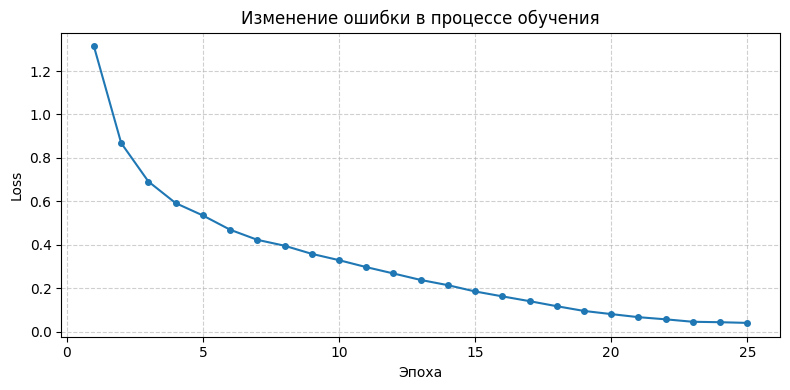

In [6]:
model.eval()
test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

test_loss /= total
test_acc = correct / total

print(f"Тестовая выборка | Loss: {test_loss:.4f} | Accuracy: {test_acc * 100:.2f}%")

plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_losses, marker='o', markersize=4)
plt.title("Изменение ошибки в процессе обучения")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()